# Day 04 · Clusters — Trader Joe's

**Research question:** What spatial structure is visible in Trader Joe's store locations across the contiguous United States, and how does that structure change when it is represented as discrete clusters versus a continuous density field?

This is an exploratory cartographic exercise for the 2026 **#30DayMapChallenge**.

**Pre-requisites**

* Download the Trader Joe's locations at [SimpleMaps Trader Joe's Locations Database](https://simplemaps.com/data/business/trader-joes).

* Download the U.S. Census Bureau's 2025 state cartographic boundary archive at [`cb_2025_us_state_20m.zip`](https://www2.census.gov/geo/tiger/GENZ2025/shp/cb_2025_us_state_20m.zip) and leave the ZIP intact. It is used for the spatial CONUS filter and state outlines.

* Obtain the [CartoDB API key](https://carto.com/basemaps/apikey/) and save the CARTO XYZ tile URL and key in secrets/readme; Positron tiles are used as a fallback.

In [19]:
from pathlib import Path
import re
import warnings

import contextily as cx
import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter
from sklearn.cluster import HDBSCAN

warnings.filterwarnings("ignore", category=UserWarning, module="contextily")

def find_project_dir():
    # Find 4_clusters whether the notebook starts at repo root or notebooks/.
    starts = [Path.cwd().resolve(), Path.cwd().resolve().parent]
    for start in starts:
        for candidate in (start, start / "4_clusters"):
            if (candidate / "data" / "trader-joes.csv").exists():
                return candidate
    raise FileNotFoundError("Could not locate 4_clusters/data/trader-joes.csv")

PROJECT_DIR = find_project_dir()
REPO_DIR = PROJECT_DIR.parent
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

# Cozy Earthy palette
OAT = "#F5F0E6"
IVORY = "#FFF9F0"
ESPRESSO = "#332C26"
TERRACOTTA = "#C76545"
PERSIMMON = "#E79B72"
OLIVE = "#85876A"
SAGE = "#B7B9A5"
TAUPE = "#C9B8A6"

# Use the repository typeface when available, then fall back cleanly.
font_name = "DejaVu Sans"
font_candidates = list((REPO_DIR / "OTF").glob("*Buch.otf"))
if font_candidates:
    mpl.font_manager.fontManager.addfont(font_candidates[0])
    font_name = mpl.font_manager.FontProperties(fname=font_candidates[0]).get_name()

mpl.rcParams.update({
    "font.family": font_name,
    "figure.facecolor": OAT,
    "axes.facecolor": OAT,
    "axes.edgecolor": TAUPE,
    "axes.labelcolor": ESPRESSO,
    "text.color": ESPRESSO,
    "xtick.color": ESPRESSO,
    "ytick.color": ESPRESSO,
    "savefig.facecolor": OAT,
    "savefig.bbox": "tight",
})

def load_carto_url():
    # Read a raster URL without displaying or storing its credential.
    config_path = REPO_DIR / "secrets" / "readme"
    if config_path.exists():
        match = re.search(r"https://[^\s]+/\{z\}/\{x\}/\{y\}\.png[^\s]*", config_path.read_text())
        if match:
            return match.group(0), "CartoDB Voyager"
    return cx.providers.CartoDB.PositronNoLabels, "CartoDB Positron (public fallback)"

BASEMAP_SOURCE, BASEMAP_NAME = load_carto_url()

def add_restrained_basemap(ax, source=BASEMAP_SOURCE, zoom=4):
    # Add tiles when online; leave the neutral canvas intact when offline.
    try:
        cx.add_basemap(ax, source=source, zoom=zoom, attribution=False, alpha=0.58)
        return BASEMAP_NAME
    except Exception as exc:
        print(f"Basemap unavailable ({type(exc).__name__}); continuing with vector boundaries.")
        return "No raster basemap (offline fallback)"

def finish_map(ax, title, subtitle, footer):
    ax.set_axis_off()
    ax.set_title(title, loc="left", fontsize=19, fontweight="bold", pad=14)
    ax.text(0, 1.005, subtitle, transform=ax.transAxes, ha="left", va="bottom", fontsize=9.5, color=OLIVE)
    ax.text(0, -0.025, footer, transform=ax.transAxes, ha="left", va="top", fontsize=7.8, color=OLIVE)

## 2 · Data inspection and validation

Discover coordinate columns rather than hard-coding a single schema. Records with missing or implausible coordinates are removed, exact duplicate coordinates are flagged, and a spatial join against U.S. Census state polygons retains the lower 48 states plus Washington, D.C.

In [20]:
csv_files = sorted(DATA_DIR.glob("*.csv"))
if not csv_files:
    raise FileNotFoundError(f"No CSV files found in {DATA_DIR}")

CSV_PATH = next((p for p in csv_files if "trader" in p.name.lower()), csv_files[0])
raw = pd.read_csv(CSV_PATH)

def find_coordinate_column(columns, kind):
    normalized = {c.lower().strip(): c for c in columns}
    candidates = {
        "latitude": ["latitude", "lat", "y"],
        "longitude": ["longitude", "lon", "lng", "long", "x"],
    }[kind]
    for candidate in candidates:
        if candidate in normalized:
            return normalized[candidate]
    raise KeyError(f"Could not identify a {kind} column from {list(columns)}")

lat_col = find_coordinate_column(raw.columns, "latitude")
lon_col = find_coordinate_column(raw.columns, "longitude")

inspection = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "unique": raw.nunique(dropna=True),
})
print(f"Source: {CSV_PATH.name}")
print(f"Rows × columns: {raw.shape[0]:,} × {raw.shape[1]}")
print(f"Detected coordinates: longitude={lon_col!r}, latitude={lat_col!r}")
print(f"Duplicate rows: {raw.duplicated().sum():,}")
display(inspection)
display(raw.head())

Source: trader-joes.csv
Rows × columns: 656 × 5
Detected coordinates: longitude='lng', latitude='lat'
Duplicate rows: 0


,dtype,missing,unique
store_name,object,0,626
city_name,object,0,495
state_id,object,0,43
lat,float64,0,636
lng,float64,0,646


,store_name,city_name,state_id,lat,lng
0,Hoover,Hoover,AL,33.379,-86.803
1,Birmingham,Birmingham,AL,33.446,-86.732
2,Huntsville,Huntsville,AL,34.740,-86.665
3,Gilbert (SanTan),Gilbert,AZ,33.306,-111.752
4,Queen Creek,Queen Creek,AZ,33.256,-111.639


In [21]:
clean = raw.copy()
clean[lat_col] = pd.to_numeric(clean[lat_col], errors="coerce")
clean[lon_col] = pd.to_numeric(clean[lon_col], errors="coerce")

valid_coordinates = (
    clean[lat_col].between(-90, 90)
    & clean[lon_col].between(-180, 180)
)
clean = clean.loc[valid_coordinates].copy()
coordinate_duplicates = clean.duplicated([lat_col, lon_col], keep=False)

stores_wgs84 = gpd.GeoDataFrame(
    clean,
    geometry=gpd.points_from_xy(clean[lon_col], clean[lat_col]),
    crs="EPSG:4326",
)

STATES_PATH = DATA_DIR / "cb_2025_us_state_20m.zip"
if not STATES_PATH.exists():
    raise FileNotFoundError(
        "Download the Census 2025 state boundary archive to data/cb_2025_us_state_20m.zip"
    )
states_wgs84 = gpd.read_file(f"zip://{STATES_PATH}").to_crs("EPSG:4326")

conus_codes = {
    "AL", "AZ", "AR", "CA", "CO", "CT", "DE", "FL", "GA", "ID",
    "IL", "IN", "IA", "KS", "KY", "LA", "ME", "MD", "MA", "MI",
    "MN", "MS", "MO", "MT", "NE", "NV", "NH", "NJ", "NM", "NY",
    "NC", "ND", "OH", "OK", "OR", "PA", "RI", "SC", "SD", "TN",
    "TX", "UT", "VT", "VA", "WA", "WV", "WI", "WY", "DC",
}
conus_states_wgs84 = states_wgs84.loc[states_wgs84["STUSPS"].isin(conus_codes)].copy()

# Intersects is boundary-safe for points that happen to lie exactly on a polygon edge.
conus_join = gpd.sjoin(
    stores_wgs84,
    conus_states_wgs84[["STUSPS", "NAME", "geometry"]],
    how="inner",
    predicate="intersects",
)
stores_conus_wgs84 = conus_join.drop(columns=["index_right"]).copy()
stores_5070 = stores_conus_wgs84.to_crs("EPSG:5070")
states_5070 = conus_states_wgs84.to_crs("EPSG:5070")

print(f"Rows removed for invalid/missing coordinates: {(~valid_coordinates).sum():,}")
print(f"Rows sharing an exact coordinate: {coordinate_duplicates.sum():,}")
print(f"Valid CONUS stores after spatial join: {len(stores_5070):,}")
print(f"Excluded outside CONUS: {len(stores_wgs84) - len(stores_5070):,}")
print(f"Analysis CRS: {stores_5070.crs}")
display(stores_conus_wgs84.groupby("STUSPS").size().rename("store_count").describe().to_frame())

Rows removed for invalid/missing coordinates: 0
Rows sharing an exact coordinate: 0
Valid CONUS stores after spatial join: 655
Excluded outside CONUS: 1
Analysis CRS: EPSG:5070


,store_count
count,43.000000
mean,15.232558
std,31.902259
min,1.000000
25%,3.000000
50%,8.000000
75%,15.500000
max,210.000000


## 3 · Visualization A — observed point distribution

This first map is descriptive: every mark is an observed store location. Overplotting already suggests concentrations, but it does not define clusters.

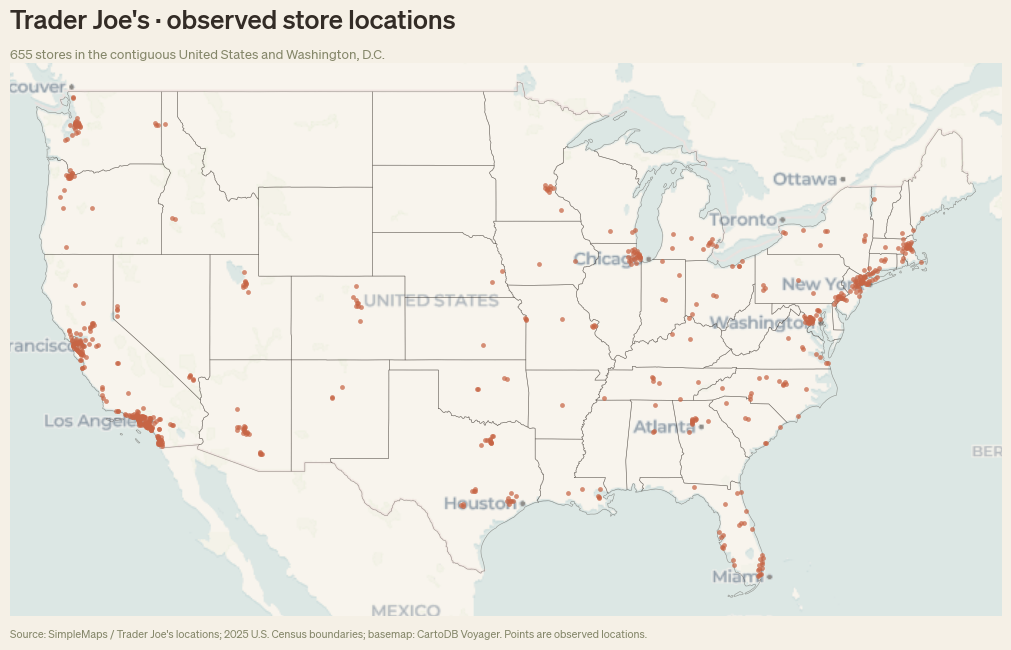

In [22]:
states_3857 = conus_states_wgs84.to_crs("EPSG:3857")
stores_3857 = stores_conus_wgs84.to_crs("EPSG:3857")
bounds_3857 = states_3857.total_bounds

fig, ax = plt.subplots(figsize=(12.8, 8.0))
states_3857.plot(ax=ax, facecolor="none", edgecolor=ESPRESSO, linewidth=0.42, alpha=0.45, zorder=2)
stores_3857.plot(ax=ax, color=TERRACOTTA, markersize=12, alpha=0.72, linewidth=0, zorder=3)
ax.set_xlim(bounds_3857[0] - 180_000, bounds_3857[2] + 180_000)
ax.set_ylim(bounds_3857[1] - 130_000, bounds_3857[3] + 130_000)
basemap_used = add_restrained_basemap(ax)
finish_map(
    ax,
    "Trader Joe's · observed store locations",
    f"{len(stores_5070):,} stores in the contiguous United States and Washington, D.C.",
    f"Source: SimpleMaps / Trader Joe's locations; 2025 U.S. Census boundaries; basemap: {basemap_used}. Points are observed locations.",
)
fig.savefig(OUTPUT_DIR / "trader_joes_points.png", dpi=300)
plt.show()

## 4 · HDBSCAN — discrete spatial clusters

**Density-based clustering** groups points that have sufficiently dense neighbourhoods and leaves isolated points unassigned. Unlike K-means, HDBSCAN does not require a preset number of clusters, does not force every store into a group, and can recover irregular shapes.

HDBSCAN does **not** ignore distance, and it does not require one global distance cutoff. For each store, it sorts the other stores by ordinary map distance and calculates a local *core distance*. In scikit-learn, `min_samples` counts the store itself, so `min_samples=3` means the store plus its two nearest other stores; the core distance reaches the second other store. This ranking is purely by spatial distance, not by a level in the later cluster hierarchy. HDBSCAN then links stores using *mutual-reachability distance*—the largest of the two core distances and the ordinary distance between the pair. It examines the resulting network across every distance scale, from tight links to loose ones, and builds a hierarchy of candidate clusters. Groups smaller than `min_cluster_size` are discarded, and the groups that persist most stably across scales are selected. That is how the observed coordinate spacing supplies the distance thresholds automatically.

- `min_cluster_size=5` says a persistent group should contain at least five stores.
- `min_samples=3` sets the nearest-neighbour scale used to estimate local density. In scikit-learn this count includes the store itself, so it reaches two other stores; larger values are more conservative and usually create more noise.
- Label `-1` means **noise** under these exploratory settings—not that the store is erroneous or unimportant.

Cluster IDs are arbitrary, and assignments can change when either parameter changes. They must not be interpreted as Trader Joe's operating or supply regions.

In [23]:
xy = np.column_stack([stores_5070.geometry.x, stores_5070.geometry.y])
hdbscan_model = HDBSCAN(min_cluster_size=5, min_samples=3)
stores_5070["cluster"] = hdbscan_model.fit_predict(xy)

clustered = stores_5070.loc[stores_5070["cluster"] >= 0]
summary_rows = []
for cluster_id, group in clustered.groupby("cluster"):
    minx, miny, maxx, maxy = group.total_bounds
    centroid_wgs84 = gpd.GeoSeries([group.union_all().centroid], crs="EPSG:5070").to_crs("EPSG:4326").iloc[0]
    summary_rows.append({
        "cluster_id": int(cluster_id),
        "store_count": len(group),
        "width_km": (maxx - minx) / 1_000,
        "height_km": (maxy - miny) / 1_000,
        "centroid_lon": centroid_wgs84.x,
        "centroid_lat": centroid_wgs84.y,
    })

cluster_summary = (
    pd.DataFrame(summary_rows)
    .sort_values(["store_count", "cluster_id"], ascending=[False, True])
    .reset_index(drop=True)
)
cluster_summary.to_csv(OUTPUT_DIR / "trader_joes_clusters_summary.csv", index=False)

noise_count = int((stores_5070["cluster"] == -1).sum())
print(f"Clusters found: {len(cluster_summary):,}")
print(f"Stores assigned to clusters: {len(clustered):,}")
print(f"Unclustered stores (noise): {noise_count:,}")
display(cluster_summary.round({"width_km": 1, "height_km": 1, "centroid_lon": 3, "centroid_lat": 3}))

Clusters found: 37
Stores assigned to clusters: 570
Unclustered stores (noise): 85


,cluster_id,store_count,width_km,height_km,centroid_lon,centroid_lat
0,19,104,183.6,134.8,-118.181,33.982
1,21,59,120.2,222.4,-122.129,37.650
2,28,30,85.9,79.9,-77.070,38.994
3,29,30,75.7,163.6,-71.194,42.361
4,32,27,65.1,173.3,-87.907,42.016
5,17,26,87.2,178.7,-122.343,47.662
6,20,21,25.7,99.4,-117.153,32.944
7,36,19,27.6,14.5,-73.976,40.748
8,16,17,94.8,168.1,-122.742,45.337
9,9,16,63.2,154.2,-112.004,33.533


### How membership is decided

HDBSCAN does not know named regions and does not assign each store to whichever finished cluster is geographically closest. It builds one hierarchy from the projected distances among **all** stores. `min_samples=3` defines the local density scale (in scikit-learn, the store itself plus its two nearest other stores), while `min_cluster_size=5` removes candidate branches that never persist with at least five members.

As the distance scale loosens, a point may remain attached to a branch that ultimately becomes a stable cluster, even when it lies on that cluster's sparse edge. This is why the two Bellingham stores can remain low-confidence fringe members of the larger Seattle branch: they are not being accepted as a two-store cluster. Conversely, points become noise when they peel away before belonging persistently to any selected branch; HDBSCAN does not attach those leftovers to the nearest cluster afterward. The solid cluster colours show the final label, not membership confidence—Bellingham's membership strengths are only about 0.09–0.10, compared with values near 1.0 in central Seattle.

In short, the algorithm combines **data-derived proximity and density across every distance scale** with the user-defined minimum cluster size. There is no single maximum joining distance, and state or metropolitan boundaries are not inputs.

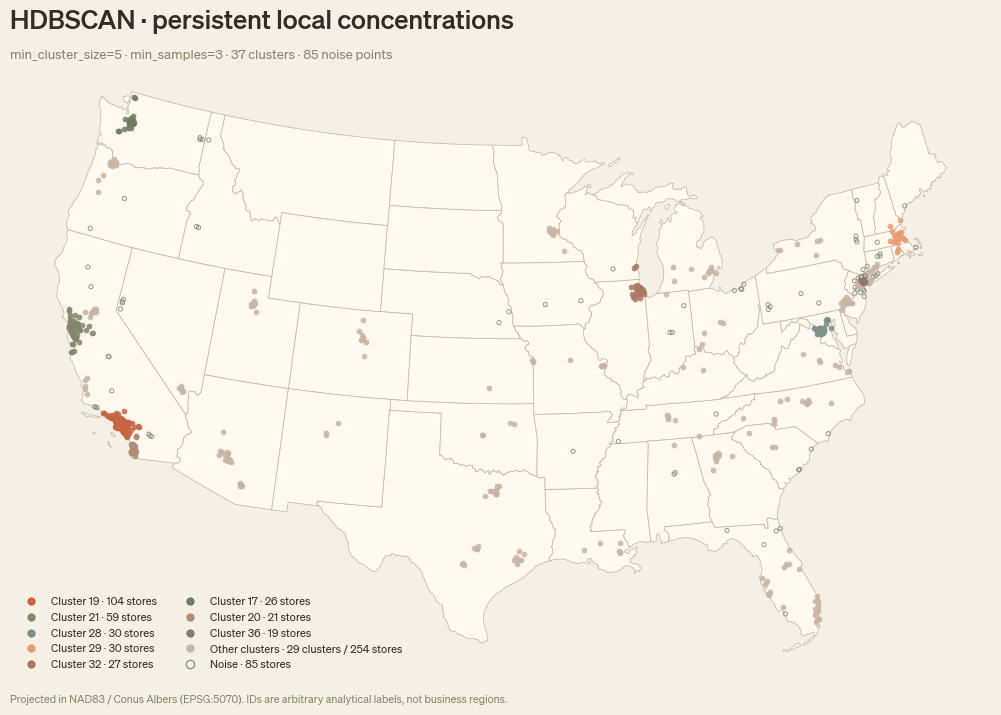

In [24]:
cluster_order = cluster_summary["cluster_id"].tolist()
restrained_colors = [TERRACOTTA, OLIVE, "#7D8F8A", PERSIMMON, "#A87862", "#6F7D62", "#B18B74", "#8F7771"]
top_clusters = cluster_summary.head(8)
top_cluster_ids = top_clusters["cluster_id"].tolist()
other_cluster_ids = cluster_summary.iloc[8:]["cluster_id"].tolist()
cluster_color = {cid: restrained_colors[i] for i, cid in enumerate(top_cluster_ids)}

top_mask = stores_5070["cluster"].isin(top_cluster_ids)
other_mask = stores_5070["cluster"].isin(other_cluster_ids)
noise_mask = stores_5070["cluster"].eq(-1)
assert not (top_mask & other_mask).any()
assert not (top_mask & noise_mask).any()
assert not (other_mask & noise_mask).any()
assert int(top_mask.sum() + other_mask.sum() + noise_mask.sum()) == len(stores_5070)

other_clusters = stores_5070.loc[other_mask]
noise = stores_5070.loc[noise_mask]
other_taupe = "#C8B5A4"
noise_sage = "#858F78"

fig, ax = plt.subplots(figsize=(12.8, 8.0))
states_5070.plot(ax=ax, facecolor=IVORY, edgecolor=TAUPE, linewidth=0.55, zorder=1)
ax.scatter(
    noise.geometry.x, noise.geometry.y,
    s=9, facecolors="none", edgecolors=noise_sage,
    linewidths=0.7, alpha=0.9, zorder=2,
)
other_clusters.plot(ax=ax, color=other_taupe, markersize=17, alpha=0.86, linewidth=0, zorder=3)
for cid in top_cluster_ids:
    group = stores_5070.loc[stores_5070["cluster"] == cid]
    group.plot(ax=ax, color=cluster_color[cid], markersize=17, alpha=0.86, linewidth=0, zorder=3)

legend_handles = [
    Line2D([0], [0], marker="o", linestyle="", markerfacecolor=cluster_color[row.cluster_id], markeredgecolor="none",
           markersize=6, label=f"Cluster {row.cluster_id} · {row.store_count} stores")
    for row in top_clusters.itertuples()
]
legend_handles.extend([
    Line2D([0], [0], marker="o", linestyle="", markerfacecolor=other_taupe, markeredgecolor="none", markersize=6,
           label=f"Other clusters · {len(other_cluster_ids)} clusters / {len(other_clusters)} stores"),
    Line2D([0], [0], marker="o", linestyle="", markerfacecolor="none", markeredgecolor=noise_sage, markeredgewidth=0.9, markersize=6,
           label=f"Noise · {len(noise)} stores"),
])
ax.legend(handles=legend_handles, loc="lower left", frameon=False, fontsize=8, ncol=2)
finish_map(
    ax,
    "HDBSCAN · persistent local concentrations",
    f"min_cluster_size=5 · min_samples=3 · {len(cluster_summary)} clusters · {noise_count} noise points",
    "Projected in NAD83 / Conus Albers (EPSG:5070). IDs are arbitrary analytical labels, not business regions.",
)
fig.savefig(OUTPUT_DIR / "trader_joes_hdbscan.png", dpi=300)
plt.show()

## 5 · Gaussian KDE — continuous density

HDBSCAN answers **which points belong together under a density rule**. KDE answers **how point intensity varies continuously across space**. Here, stores are first counted into a 10 km grid, then smoothed with a Gaussian kernel. A bandwidth in kilometres is converted to grid cells (`sigma = bandwidth / cell_size`).

Dividing the smoothed count by cell area expresses the result as **stores per 100 km²**. Padding keeps edge loss small; the mass check below verifies that the smoothed surface approximately preserves the number of stores.

In [25]:
CELL_SIZE_M = 10_000  # 10 km; each cell is 100 km²
PADDING_M = 200_000
minx, miny, maxx, maxy = states_5070.total_bounds
x_edges = np.arange(minx - PADDING_M, maxx + PADDING_M + CELL_SIZE_M, CELL_SIZE_M)
y_edges = np.arange(miny - PADDING_M, maxy + PADDING_M + CELL_SIZE_M, CELL_SIZE_M)

counts, _, _ = np.histogram2d(
    stores_5070.geometry.x,
    stores_5070.geometry.y,
    bins=[x_edges, y_edges],
)
counts = counts.T  # array rows follow y; columns follow x

def kde_density(bandwidth_km, point_counts=counts):
    sigma_cells = (bandwidth_km * 1_000) / CELL_SIZE_M
    smoothed_counts = gaussian_filter(point_counts, sigma=sigma_cells, mode="constant")
    density_per_100km2 = smoothed_counts / cell_area_km2 * 100
    return density_per_100km2, smoothed_counts.sum()

def contour_levels(surface, n=6):
    positive = surface[surface > surface.max() * 0.01]
    levels = np.quantile(positive, np.linspace(0.15, 0.95, n))
    return np.unique(levels)


x_centres = (x_edges[:-1] + x_edges[1:]) / 2
y_centres = (y_edges[:-1] + y_edges[1:]) / 2
X, Y = np.meshgrid(x_centres, y_centres)
cell_area_km2 = (CELL_SIZE_M / 1_000) ** 2


bandwidths = [15, 30, 50]
kde_surfaces = {bw: kde_density(bw)[0] for bw in bandwidths}
mass_check = pd.DataFrame([
    {
        "bandwidth_km": bw,
        "input_stores": int(counts.sum()),
        "smoothed_mass": kde_density(bw)[1],
        "mass_retained_pct": 100 * kde_density(bw)[1] / counts.sum(),
    }
    for bw in bandwidths
])
display(mass_check.round({"smoothed_mass": 2, "mass_retained_pct": 2}))

kde_cmap = LinearSegmentedColormap.from_list(
    "cozy_density", [IVORY, "#F0D7BF", PERSIMMON, TERRACOTTA, "#7B493B"]
)

main_density = kde_surfaces[30]
main_levels = contour_levels(main_density)
print("30 km contour thresholds (stores per 100 km²):", np.round(main_levels, 3).tolist())

,bandwidth_km,input_stores,smoothed_mass,mass_retained_pct
0,15,655,655.0,100.0
1,30,655,655.0,100.0
2,50,655,655.0,100.0


30 km contour thresholds (stores per 100 km²): [0.012, 0.016, 0.022, 0.033, 0.059, 0.207]


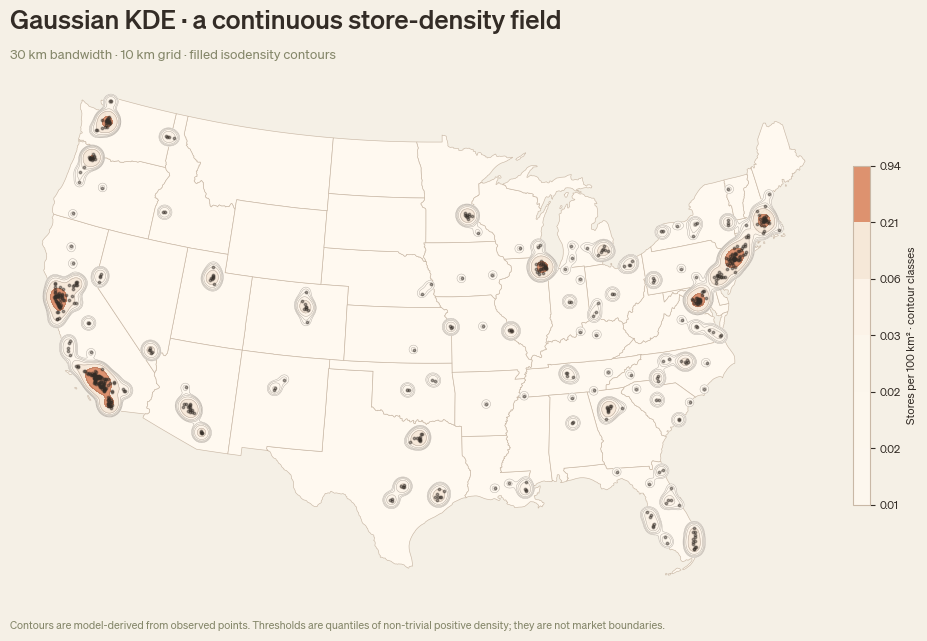

In [26]:
fig, ax = plt.subplots(figsize=(12.8, 8.0))
states_5070.plot(ax=ax, facecolor=IVORY, edgecolor=TAUPE, linewidth=0.45, zorder=1)
filled = ax.contourf(X, Y, main_density, levels=np.r_[main_levels, main_density.max() + 1e-9], cmap=kde_cmap, alpha=0.88, zorder=2)
ax.contour(X, Y, main_density, levels=main_levels, colors=ESPRESSO, linewidths=0.35, alpha=0.35, zorder=3)
stores_5070.plot(ax=ax, color=ESPRESSO, markersize=3.2, alpha=0.44, zorder=4)
cbar = fig.colorbar(filled, ax=ax, shrink=0.55, pad=0.015, format="%.2f",)
cbar.set_label("Stores per 100 km² · contour classes", fontsize=8)
cbar.ax.tick_params(labelsize=8)

finish_map(
    ax,
    "Gaussian KDE · a continuous store-density field",
    "30 km bandwidth · 10 km grid · filled isodensity contours",
    "Contours are model-derived from observed points. Thresholds are quantiles of non-trivial positive density; they are not market boundaries.",
)
fig.savefig(OUTPUT_DIR / "trader_joes_kde.png", dpi=300)
plt.show()

## 6 · Bandwidth comparison

Bandwidth is the main visual and analytical control. At **15 km**, local concentrations remain separate and detailed. At **30 km**, nearby concentrations begin to merge into rounded, metaball-like forms. At **50 km**, regional patterns dominate and local distinctions soften. None is automatically “correct”; the appropriate scale depends on the question.

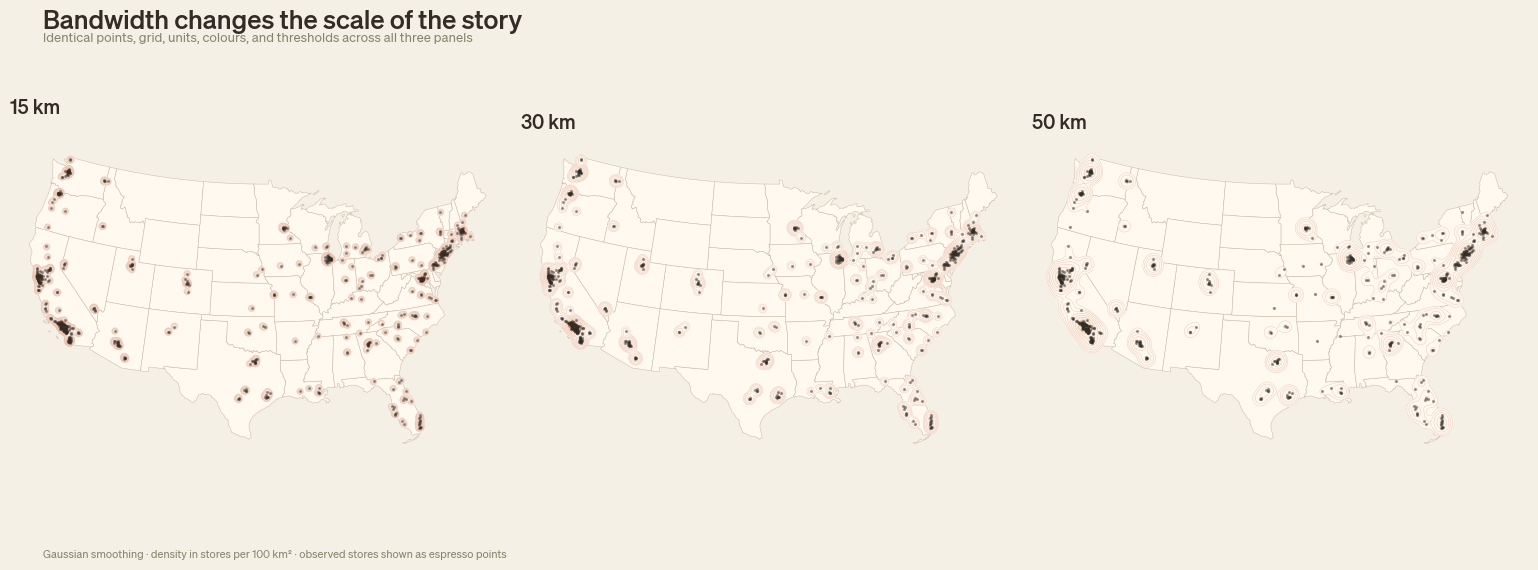

In [27]:
# A logarithmic shared scale preserves comparability while keeping the
# broad 50 km surface visible beside the much sharper 15 km peaks.
comparison_max = max(surface.max() for surface in kde_surfaces.values())
shared_ceiling = min(surface.max() for surface in kde_surfaces.values())
shared_floor = min(
    np.quantile(surface[surface > surface.max() * 0.01], 0.15)
    for surface in kde_surfaces.values()
)
shared_levels = np.geomspace(shared_floor, shared_ceiling, 8)
fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.8), sharex=True, sharey=True)
for ax, bw in zip(axes, bandwidths):
    states_5070.plot(ax=ax, facecolor=IVORY, edgecolor=TAUPE, linewidth=0.35, zorder=1)
    surface = kde_surfaces[bw]
    ax.contourf(X, Y, surface, levels=np.r_[shared_levels, comparison_max + 1e-9], cmap=kde_cmap, alpha=0.9, zorder=2)
    ax.contour(X, Y, surface, levels=shared_levels, colors=TERRACOTTA, linewidths=0.3, alpha=0.35, zorder=3)
    stores_5070.plot(ax=ax, color=ESPRESSO, markersize=1.7, alpha=0.38, zorder=3)
    ax.set_title(f"{bw} km", loc="left", fontsize=14, fontweight="bold")
    ax.set_axis_off()
fig.suptitle("Bandwidth changes the scale of the story", x=0.08, ha="left", fontsize=19, fontweight="bold")
fig.text(0.08, 0.925, "Identical points, grid, units, colours, and thresholds across all three panels", fontsize=9.5, color=OLIVE)
fig.text(0.08, 0.035, "Gaussian smoothing · density in stores per 100 km² · observed stores shown as espresso points", fontsize=8, color=OLIVE)
fig.subplots_adjust(left=0.06, right=0.98, top=0.88, bottom=0.08, wspace=0.03)
fig.savefig(OUTPUT_DIR / "trader_joes_kde_bandwidth_comparison.png", dpi=300)
plt.show()

## 7 · Combined view — HDBSCAN-informed KDE

HDBSCAN and KDE can be combined without confusing their roles: HDBSCAN first selects stores assigned to persistent clusters; the **same** Gaussian smoothing then turns those selected points into a continuous surface. HDBSCAN does not produce the contour polygons.

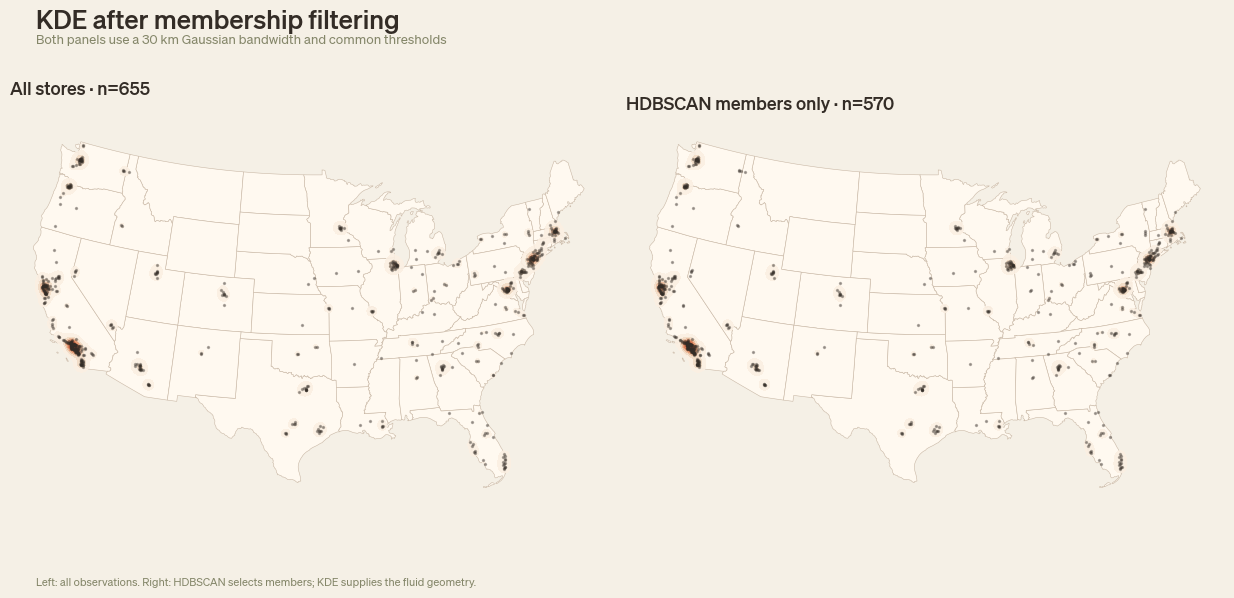

In [28]:
clustered_counts, _, _ = np.histogram2d(
    clustered.geometry.x,
    clustered.geometry.y,
    bins=[x_edges, y_edges],
)
clustered_counts = clustered_counts.T
clustered_density, clustered_mass = kde_density(30, clustered_counts)

combined_max = max(main_density.max(), clustered_density.max())
combined_levels = np.linspace(combined_max * 0.03, combined_max, 8)
fig, axes = plt.subplots(1, 2, figsize=(13.2, 6.1), sharex=True, sharey=True)
for ax, surface, label in zip(
    axes,
    [main_density, clustered_density],
    [f"All stores · n={len(stores_5070)}", f"HDBSCAN members only · n={len(clustered)}"],
):
    states_5070.plot(ax=ax, facecolor=IVORY, edgecolor=TAUPE, linewidth=0.4, zorder=1)
    ax.contourf(X, Y, surface, levels=np.r_[combined_levels, combined_max + 1e-9], cmap=kde_cmap, alpha=0.9, zorder=2)
    stores_5070.plot(ax=ax, color=ESPRESSO, markersize=2.0, alpha=0.35, zorder=3)
    ax.set_title(label, loc="left", fontsize=13, fontweight="bold")
    ax.set_axis_off()
fig.suptitle("KDE after membership filtering", x=0.08, ha="left", fontsize=19, fontweight="bold")
fig.text(0.08, 0.925, "Both panels use a 30 km Gaussian bandwidth and common thresholds", fontsize=9.5, color=OLIVE)
fig.text(0.08, 0.035, "Left: all observations. Right: HDBSCAN selects members; KDE supplies the fluid geometry.", fontsize=8, color=OLIVE)
fig.subplots_adjust(left=0.06, right=0.98, top=0.88, bottom=0.08, wspace=0.03)
fig.savefig(OUTPUT_DIR / "trader_joes_hdbscan_informed_kde.png", dpi=300)
plt.show()

## 8 · Interpretations

- The points are observed store locations; HDBSCAN labels and KDE contours are model-derived representations.
- HDBSCAN is useful for membership and noise; KDE is useful for intensity and visual continuity. Their outputs answer different questions.
- Results depend on the date and completeness of the input CSV, the projected CRS, HDBSCAN settings, grid resolution, bandwidth, and contour thresholds.
- Store locations alone do not establish retail demand, market potential, supply-chain assignments, socioeconomic causation, or company strategy.
- Census state polygons provide a defensible CONUS filter but do not correct coordinate errors inside those polygons.
- Raster tiles may be unavailable offline; the analytical layers and exports still work with vector state boundaries.

**Next steps:** check the source date against the current store locator; experiment with HDBSCAN parameters and 20–40 km KDE bandwidths; refine annotations in a vector editor if preparing a final poster; and document any manual design changes separately from the analysis.